# This notebook is intended to demonstrate some useful cheminformatic transformations to help you with handling the Dy in the molecules.

In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
!pip install mapply

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 24.5 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 11.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 14.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.4/345.4 kB 20.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 14.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 6.3 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 1.5.3
    Uninstalling pandas-1.5.3:
      Successfully uninstalled pandas-1.5.3


In [3]:
import mapply

/Users/mynguyen/opt/anaconda3/envs/my-rdkit-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.4/34.4 MB 43.3 MB/s eta 0:00:00


In [4]:
from rdkit import Chem
from rdkit.Chem import Draw, AllChem

In [29]:
#Let's load the molecule_smiles column of the test set, since it's smaller than train and this is just a demo.
test = pd.read_csv('../data/test.csv',usecols=['molecule_smiles'],)
train = pd.read_csv('../data/train_BRD4_1M_posrate-0.05.csv',usecols=['molecule_smiles', 'molecule_smiles_mod'],)

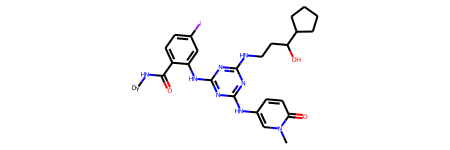

In [33]:
row=10
train_mol = Chem.MolFromSmiles(train['molecule_smiles'].iloc[row])
train_mol


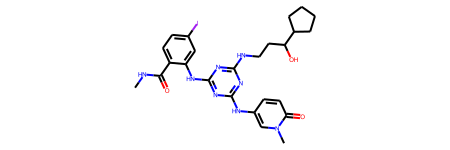

In [35]:
train_mol_mod = Chem.MolFromSmiles(train['molecule_smiles_Bu'].iloc[row])
train_mol_mod

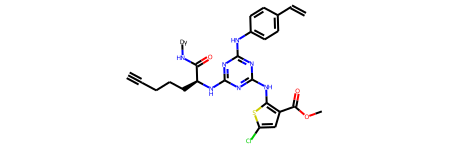

In [36]:
#Let's take a look at the first molecule in the dataframe
test_molecule = Chem.MolFromSmiles(test['molecule_smiles'].iloc[10])
test_molecule

Looks good! It's not exactly a real molecule though. That Dy is useful for helping us keep track of where the DNA is attached to this molecule, but it's likely going to get in our way if we want to convert this to a 3D structure that has some physical meaning.

Let's replace the Dy with a methyl group (-CH3).

In [37]:
#We need to generate a molecule object that we can use to create our methyl group.
Me = Chem.MolFromSmiles('CCCC')

#Now let's create a molecule object that represents the Dy atom. We can use this as a pattern we'd like to replace (below).
Dy = Chem.MolFromSmiles('[Dy]')

#Let's use these groups to replace the Dy on our test molecule with CH3.
new_mol = AllChem.ReplaceSubstructs(test_molecule, Dy, Me)
new_mol

(<rdkit.Chem.rdchem.Mol at 0x194059820>,)

Note that the output of the above cell is a tuple with one entry. This is a helpful hint that this function could have returned more than one possibility. In this case, the replacement was pretty simple so we can just access the first element and call it a day.

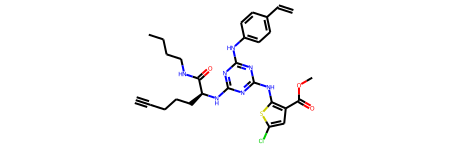

In [38]:
#Access the first element of the tuple
new_mol = new_mol[0]
#Sanitization is just a good habit after replacements/reactions as sometimes things get a little wonky.
Chem.SanitizeMol(new_mol)
#Let's check out our new molecule
new_mol

In [20]:
# write SMILES of new_mol
new_mol_smiles = Chem.MolToSmiles(new_mol)
print('New molecule: ', new_mol_smiles)
print('Old molecule: ', test['molecule_smiles'].iloc[0])

New molecule:  C#CCCC[C@H](Nc1nc(Nc2ccc(C=C)cc2)nc(Nc2ccc(C=C)cc2)n1)C(=O)NC
Old molecule:  C#CCCC[C@H](Nc1nc(Nc2ccc(C=C)cc2)nc(Nc2ccc(C=C)cc2)n1)C(=O)N[Dy]


Great, the Dy was replaced with a methyl group. A methyl group is a nice replacement if you want to do some 3D structure generations because it doesn't have many conformers (keeps things simple), but it might not do a good job of representing the linker used to attach DNA to our molecules. I haven't tested this hypothesis, but it's on my list of things to do. Regardless, knowing how to handle more complex transforms might be valuable to you in this competition.

Let's take a look at something a bit more complicated and replace the Dy group with an ethylene glycol derived linker (a little closer to what was likely used as a linker on DNA).

Here's a useful link for generating SMILES or SMARTS strings from things you can draw: https://pubchem.ncbi.nlm.nih.gov//edit3/index.html

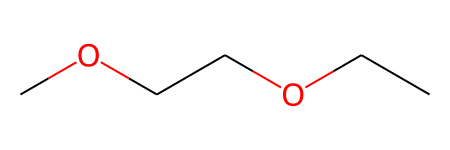

In [21]:
#Let's create a linker molecule, just like we did above for the methyl replacement.
linker = Chem.MolFromSmiles('C(COC)OCC')
linker

In [22]:
#Let's try replacing our Dy with this group
new_mol = AllChem.ReplaceSubstructs(test_molecule, Dy, linker)
new_mol

(<rdkit.Chem.rdchem.Mol at 0x175494b30>,)

That's neat. It only made one new molecule, even though we didn't have a good way of telling it where to attach. Something doesn't seem right.

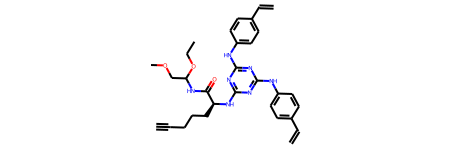

In [23]:
#Let's visualize our new molecule
Chem.SanitizeMol(new_mol[0])
new_mol[0]

Hmm...That's certainly a perfectly viable molecule someone could make, but it wasn't really what we were going for.

To fix this, we'll need to be a bit more specific. While the ReplaceSubstructs function is a very useful RDKit functionality, it works best when you're doing simple transformations. For more complex transformations, we'll need to learn a little about how to run virtual reactions.

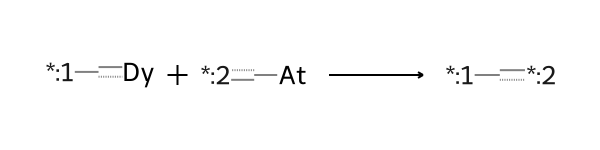

In [13]:
#Let's define a reaction object using a SMARTS string.
rxn = AllChem.ReactionFromSmarts('[*:1][Dy].[At][*:2]>>[*:1][*:2]')
rxn

Let's break down that SMARTS string a little bit. 

The >> delineates what's on the left and the right sides of the reaction.

the * means "any atom" and the ':number' maps the reactants to the products so the algorithm knows what is going where.

So, what we're saying here is essentially this: any atom bound to Dy will form a new bond to any atom bound to At.

Of course, this isn't a real world reaction; it's just virtual. But that's what's great about it! Since it's not a reaction that exists in the real world, we can use it as a virtual reaction that allows us to do virtual transformations that are very specific!

If you want to learn more about SMARTS patterns, this is a great place to start: https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html

Let's use this reaction to attach our linker.

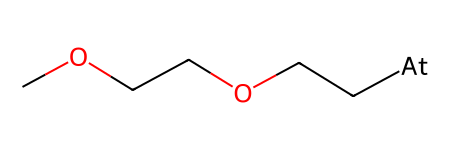

In [14]:
#First, we need to get a linker that has an At on it, signifying where we'd like it to react under our reaction scheme.
new_linker = Chem.MolFromSmiles('COCCOCC[At]')
new_linker

In [15]:
#Now let's use our reaction object to transform our test molecule with our linker.
#Note: the way we defined the reaction, the molecule with Dy should be on the left and the molecule with At should be on the right.
new_mol = rxn.RunReactants((test_molecule, new_linker))
new_mol

((<rdkit.Chem.rdchem.Mol at 0x7e1166741d90>,),)

We see now that our new_mol is a tuple of tuples. Having a tuple of tuples as an output is pretty useful for more complex reactions as there are often many places your reaction could theoretically have taken place, but we were really specific with our virtual imaginary reaction so we know there will only be one product here.

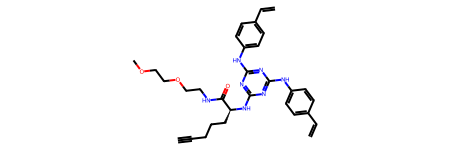

In [16]:
#Let's take a look at the molecule
new_mol = new_mol[0][0]
#Good habit to sanitize after reactions
Chem.SanitizeMol(new_mol)
new_mol

Excellent! We can now replace our Dy atom with whatever we want!

Let's write a little function that will apply this to a dataframe of our choice.

In [17]:
def run_reaction(SMILES, linker, reaction):
    """
    This function takes a SMILES string, a linker, and a reaction object and runs a virtual reaction between the SMILES input molecule and the linker.
    
    SMILES(str): The SMILES string of the molecule you'd like to transform.
    
    linker(obj): The linker you'd like to attach to the molecule, as a RDKit mol object.
    
    reaction(obj): The reaction object that represents the virtual reaction.
    ___________
    returns(str): The SMILES string for the transformed molecule.
    
    """
    #Convert the SMILES to a molecule object
    mol = Chem.MolFromSmiles(SMILES)
    
    #Run the reaction between the molecule object and the linker
    products = reaction.RunReactants((mol,linker))
    
    #Get the first product of the reaction. If this was defined similarly to above, it should be the only product
    product = products[0][0]
    
    #Good hygene
    Chem.SanitizeMol(product)
    
    #Return the molecule object as a SMILES string
    return Chem.MolToSmiles(product)

In [18]:
#Let's use mapply to transform the test set in parallel
#Thanks to Hengck23 for the tip about mapply!
#See: https://www.kaggle.com/competitions/leash-BELKA/discussion/492846

#Initialize mapply to use all of our CPU cores and provide us a progress bar.
mapply.init(
    n_workers=-1,
    progressbar=True,
)

In [19]:
#Let's run our virtual reaction using the new_linker and rxn we previously wrote. This takes a little while...
test['molecule_smiles'] = test['molecule_smiles'].mapply(lambda x: run_reaction(x, new_linker, rxn))

  0%|          | 0/24 [00:00<?, ?it/s]

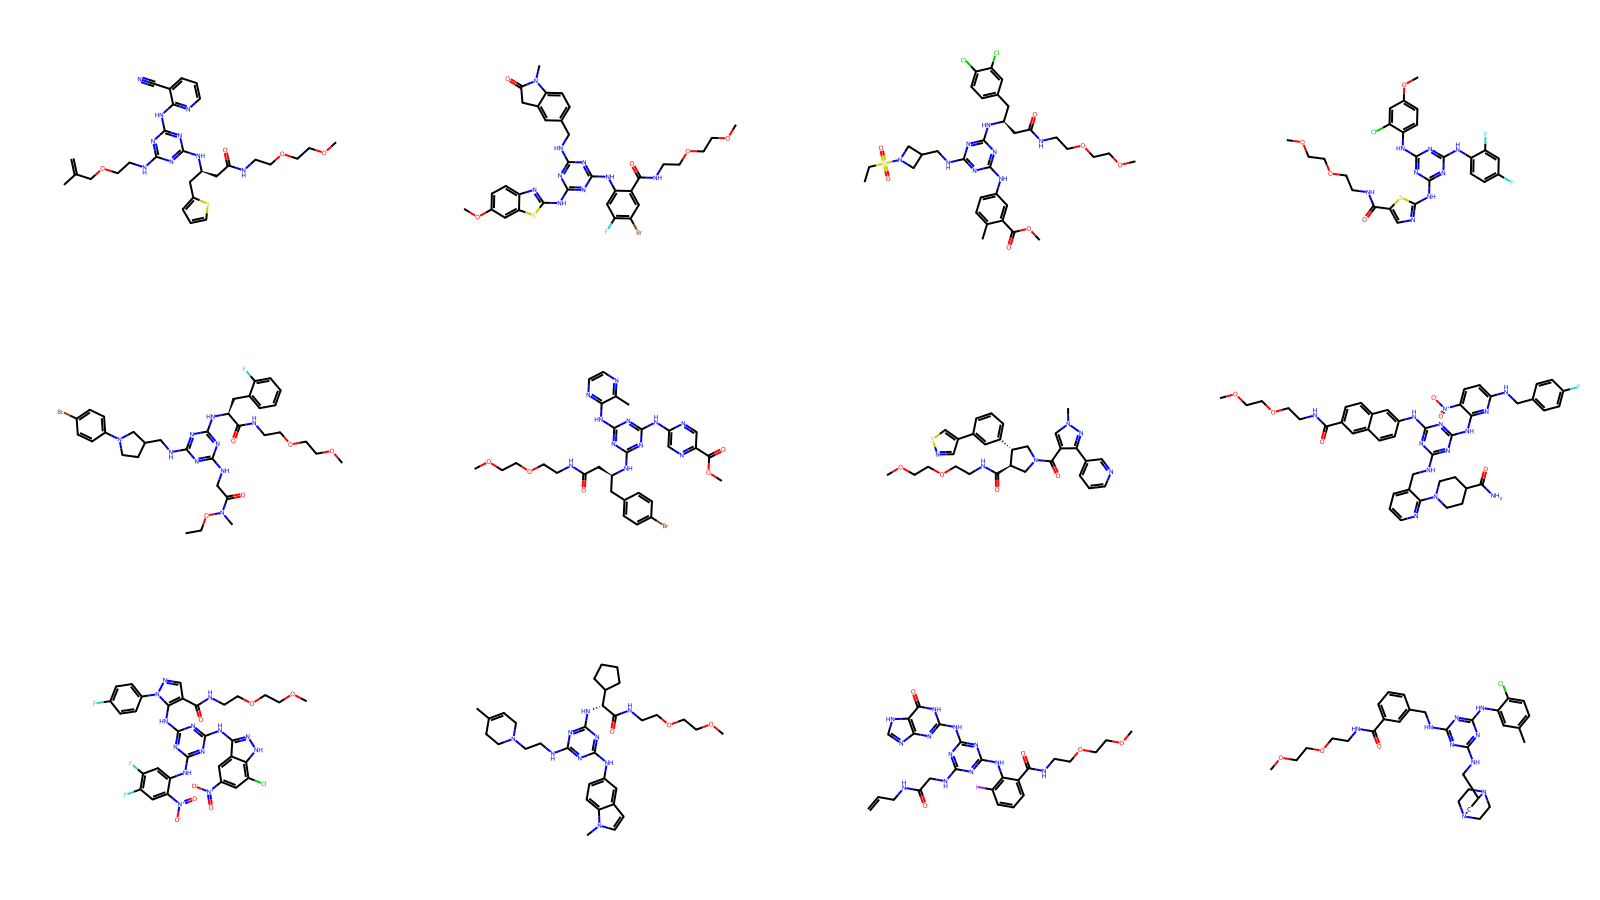

In [20]:
#Let's take a look at some of the molecules we've created
Draw.MolsToGridImage([Chem.MolFromSmiles(x) for x in test['molecule_smiles'].sample(12)], molsPerRow=4, subImgSize=(400,300))